# Comparing Different Search Strategies: Maze

Notes on breaking ties: 

* The order in which the children are explored (see `available directions`) makes a big difference for DFS and dealing with empty spaces. I explore the directions in random order which makes the algorithm stochastic!
* Ties for $h(n)$ and $f(n)$ need to be broken in a consistent manner. I use the most recently added node. To try to keep moving into the same direction.



Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).
Position(0,0): X
Position(8,1):  


<Figure size 640x480 with 0 Axes>

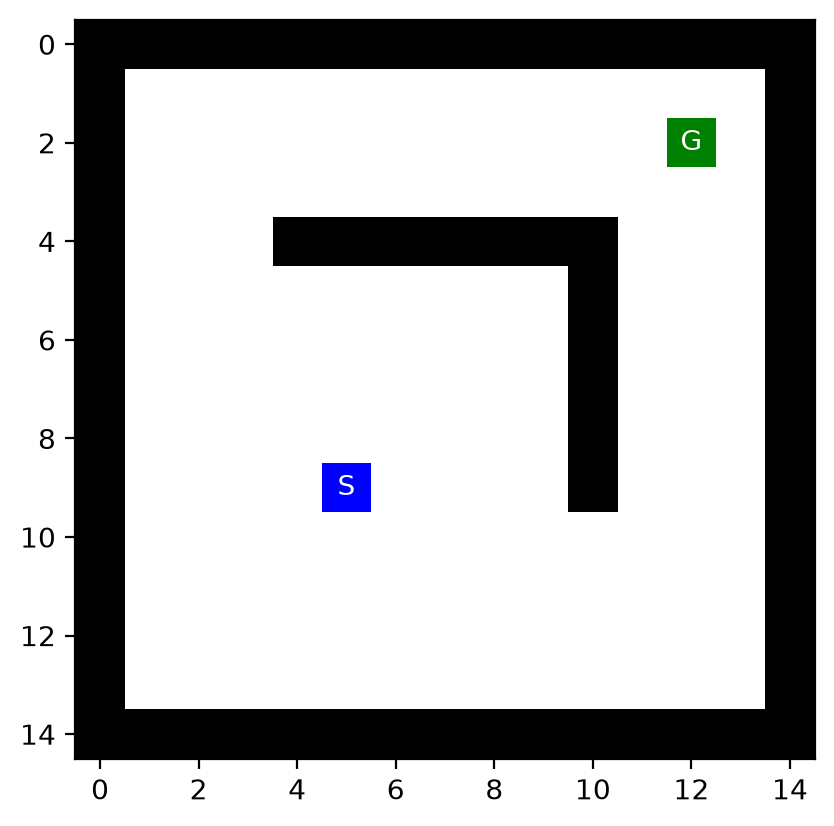

In [478]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

# look at two positions in the maze
print("Position(0,0):", maze[0, 0])
print("Position(8,1):", maze[8, 1])

show_maze(maze)

## Implementation

My implementation follows the pseudo code from the slides/textbook.

In [479]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

Directions are checked in the order ['N', 'E', 'S', 'W']


## Experiments

### BFS

Directions are checked in the order ['N', 'E', 'S', 'W']
CPU times: total: 15.6 ms
Wall time: 2.55 ms
Path length: 16
Reached squares: 152
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E']


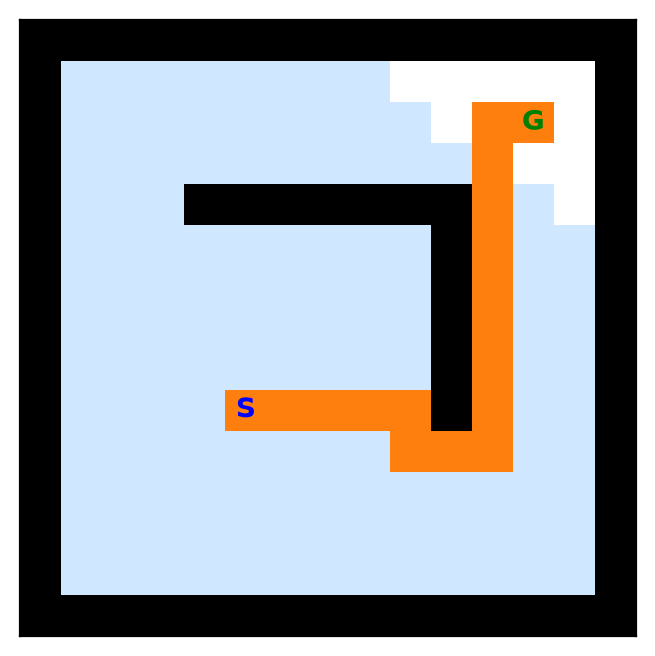

['E',
 'E',
 'E',
 'E',
 'S',
 'E',
 'E',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'E']

In [480]:
ts.set_order("NESW")
#ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "BFS", debug = False, vis = False)
ts.show_path(maze, result)
result['actions']

### DFS 

This implementation uses not reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we will end up in an infinite loop. Here are possible solutions:
* Stop after a fixed number of tries and return no solution `max_tries`.
* IDS solves this problem.

Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory!

Directions are checked in the order ['N', 'E', 'S', 'W']
CPU times: total: 0 ns
Wall time: 3.01 ms
Path length: 122
Reached squares: 133
Action sequence: ['W', 'W', 'W', 'W', 'S', 'S', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'E', 'E', 'E', 'N', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'E', 'E', 'N', 'W', 'W', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'W', 'N', 'E', 'N', 'W', 'N', 'E', 'N', 'W', 'N', 'E', 'N', 'W']


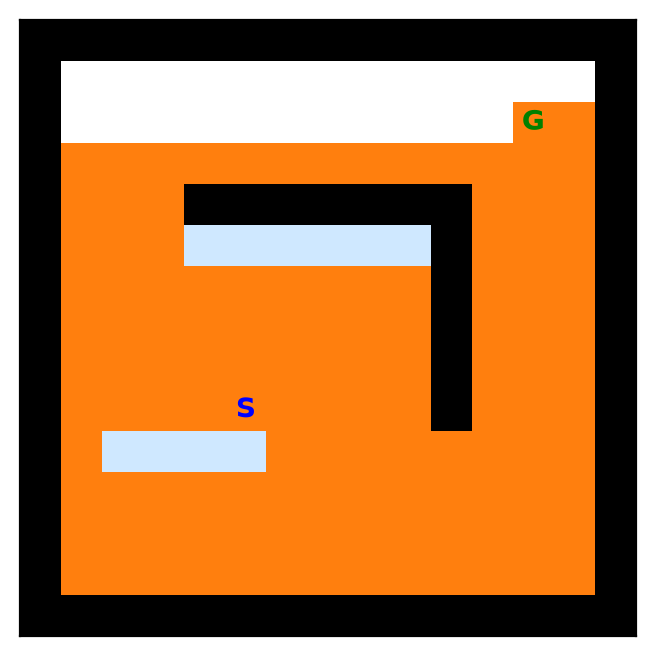

In [481]:
# Note: DFS uses LIFO so the directions come from the stack in reverse order!

# Can get stuck for empty maze since cycle checking is not string enough! 
# I use a maximum number of tries and stop if the goal is not reached.
ts.set_order("NESW")
#ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

Do the same, but change the order in which we explore states (add them to them as nodes to the frontier).

Directions are checked in the order ['S', 'E', 'N', 'W']
CPU times: total: 0 ns
Wall time: 0 ns
Path length: 26
Reached squares: 27
Action sequence: ['W', 'W', 'W', 'W', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'W']


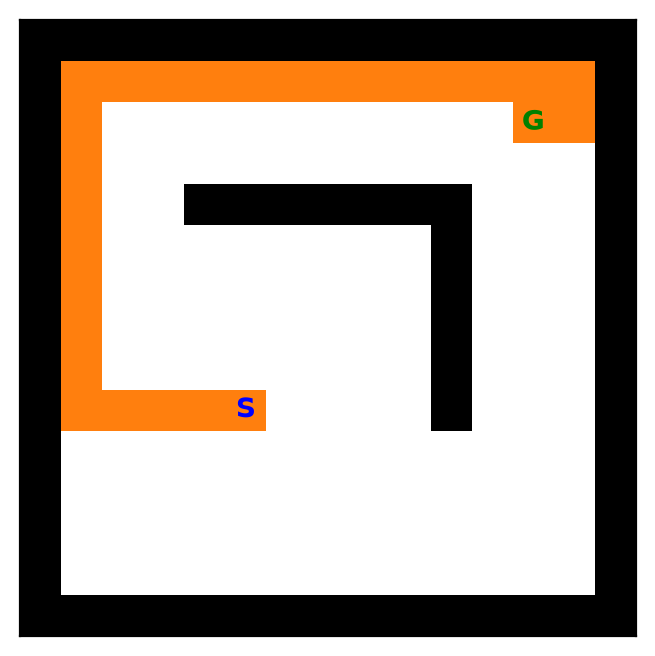

In [482]:
#ts.set_order("NESW")
ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

We could do a random walk and not check for cycles. This is guaranteed to reach eventually any square including the goal, 
but creates a long path. The path could be simplified leading to the [Tremaux's algorithm](https://en.wikipedia.org/wiki/Maze_solving_algorithm).

Directions are checked in random order
CPU times: total: 15.6 ms
Wall time: 14.7 ms
Path length: 1004
Reached squares: 110
Action sequence: ['N', 'N', 'E', 'N', 'E', 'S', 'W', 'S', 'N', 'W', 'S', 'S', 'S', 'S', 'N', 'E', 'S', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'W', 'E', 'W', 'W', 'S', 'E', 'N', 'N', 'E', 'W', 'S', 'N', 'W', 'S', 'N', 'S', 'N', 'S', 'N', 'E', 'E', 'S', 'W', 'S', 'W', 'W', 'W', 'S', 'S', 'E', 'N', 'E', 'N', 'W', 'W', 'W', 'W', 'S', 'N', 'N', 'S', 'N', 'W', 'S', 'E', 'S', 'N', 'N', 'N', 'N', 'W', 'N', 'W', 'E', 'N', 'S', 'S', 'S', 'E', 'E', 'N', 'W', 'E', 'S', 'S', 'E', 'W', 'N', 'W', 'S', 'S', 'N', 'E', 'W', 'S', 'E', 'E', 'W', 'S', 'S', 'E', 'E', 'W', 'N', 'E', 'S', 'N', 'N', 'S', 'E', 'S', 'N', 'S', 'N', 'N', 'E', 'W', 'S', 'S', 'N', 'W', 'E', 'W', 'W', 'W', 'S', 'W', 'S', 'N', 'W', 'N', 'W', 'N', 'E', 'S', 'W', 'N', 'N', 'S', 'S', 'E', 'W', 'S', 'E', 'W', 'N', 'N', 'S', 'S', 'E', 'N', 'E', 'E', 'W', 'E', 'W', 'S', 'E', 'N', 'N', 'N', 'S', 'E', 'N', 'S', 'W', 'W', 'W',

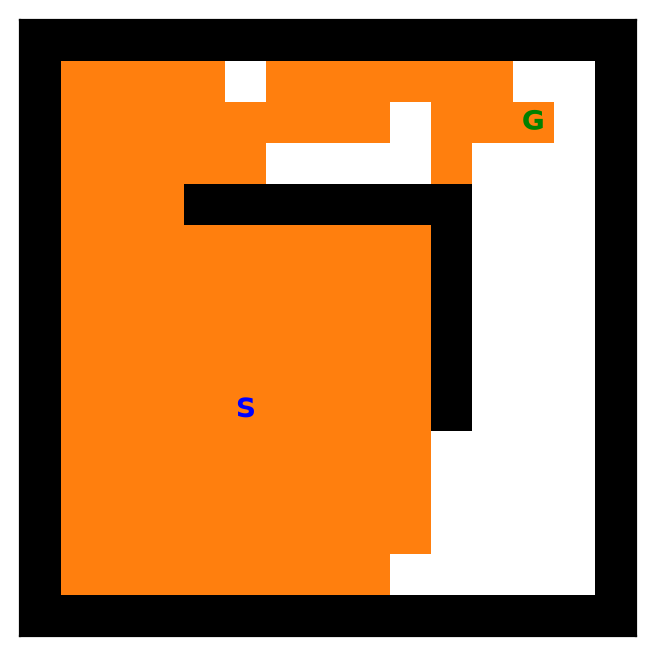

CPU times: total: 15.6 ms
Wall time: 9.24 ms
Path length: 790
Reached squares: 130
Action sequence: ['S', 'N', 'S', 'N', 'W', 'S', 'W', 'W', 'N', 'S', 'S', 'N', 'S', 'E', 'E', 'N', 'E', 'E', 'S', 'S', 'E', 'E', 'E', 'W', 'W', 'S', 'E', 'N', 'E', 'W', 'N', 'E', 'S', 'E', 'E', 'N', 'E', 'W', 'E', 'N', 'S', 'N', 'W', 'W', 'E', 'S', 'S', 'W', 'S', 'N', 'S', 'N', 'W', 'S', 'N', 'W', 'S', 'E', 'W', 'N', 'W', 'E', 'N', 'E', 'E', 'W', 'S', 'W', 'S', 'N', 'E', 'S', 'E', 'N', 'N', 'W', 'W', 'N', 'W', 'W', 'N', 'E', 'S', 'N', 'N', 'S', 'N', 'W', 'N', 'S', 'E', 'N', 'S', 'E', 'S', 'S', 'S', 'W', 'W', 'E', 'W', 'W', 'E', 'S', 'N', 'N', 'W', 'E', 'W', 'E', 'E', 'S', 'E', 'W', 'W', 'W', 'S', 'N', 'W', 'E', 'E', 'N', 'S', 'S', 'N', 'E', 'E', 'N', 'W', 'W', 'N', 'N', 'W', 'E', 'W', 'E', 'S', 'E', 'E', 'S', 'S', 'W', 'S', 'E', 'E', 'W', 'W', 'E', 'S', 'N', 'W', 'W', 'S', 'W', 'W', 'W', 'E', 'N', 'N', 'N', 'W', 'N', 'E', 'E', 'W', 'S', 'S', 'E', 'W', 'N', 'E', 'E', 'N', 'W', 'S', 'W', 'N', 'N', 'E', 'N',

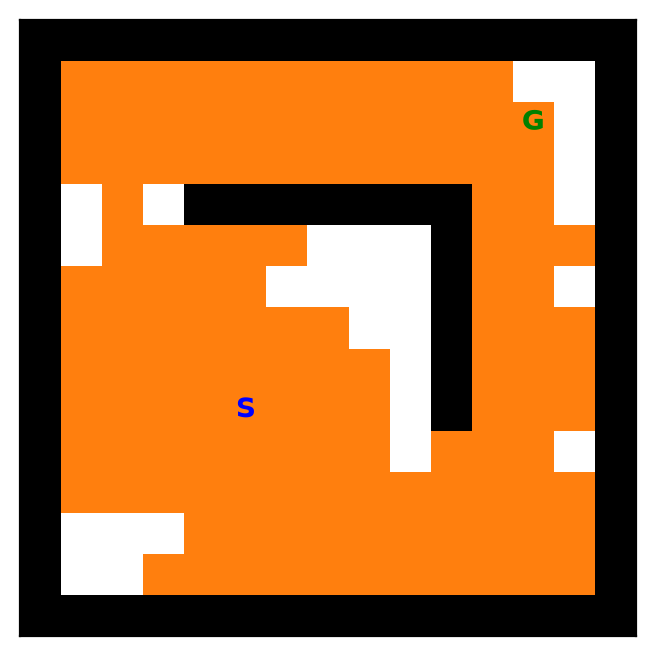

CPU times: total: 0 ns
Wall time: 3.12 ms
Path length: 290
Reached squares: 90
Action sequence: ['W', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'E', 'E', 'W', 'S', 'W', 'E', 'W', 'W', 'E', 'N', 'S', 'N', 'W', 'W', 'N', 'E', 'N', 'W', 'S', 'E', 'W', 'S', 'W', 'E', 'W', 'W', 'E', 'S', 'E', 'N', 'E', 'W', 'E', 'S', 'W', 'N', 'W', 'E', 'W', 'N', 'S', 'S', 'W', 'E', 'N', 'W', 'S', 'W', 'N', 'N', 'S', 'S', 'N', 'E', 'W', 'N', 'N', 'N', 'S', 'N', 'S', 'N', 'S', 'N', 'E', 'S', 'W', 'E', 'E', 'E', 'W', 'E', 'E', 'N', 'E', 'S', 'W', 'N', 'W', 'W', 'W', 'S', 'W', 'E', 'E', 'E', 'E', 'N', 'E', 'S', 'N', 'E', 'N', 'N', 'N', 'S', 'S', 'N', 'S', 'S', 'W', 'N', 'N', 'S', 'W', 'N', 'E', 'N', 'S', 'N', 'S', 'E', 'S', 'W', 'W', 'E', 'S', 'S', 'N', 'S', 'E', 'W', 'N', 'E', 'E', 'N', 'E', 'N', 'W', 'N', 'S', 'S', 'E', 'S', 'W', 'W', 'S', 'E', 'W', 'W', 'S', 'W', 'E', 'W', 'W', 'N', 'E', 'S', 'E', 'S', 'N', 'E', 'E', 'W', 'N', 'E', 'E', 'W', 'N', 'E', 'S', 'E', 'S', 'E', 'W', 'N', 'E', 'E', 'W', 'N', 'S', 'E', 'S'

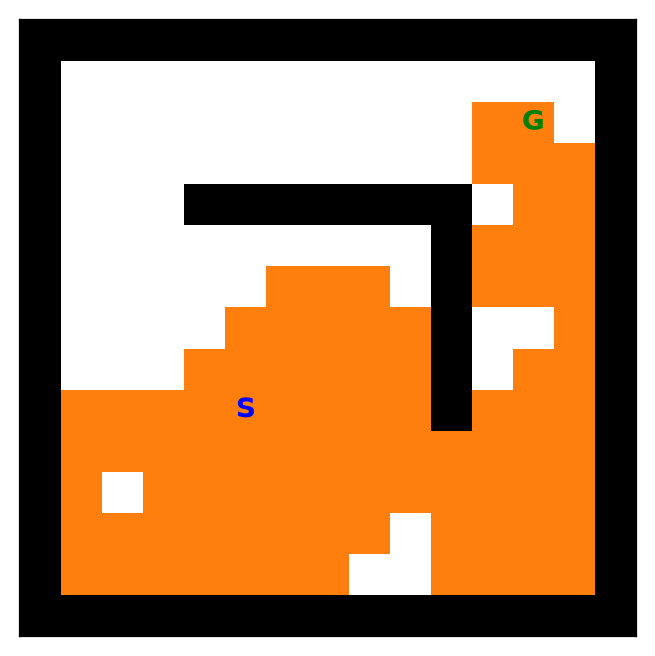

CPU times: total: 0 ns
Wall time: 4.51 ms
Path length: 496
Reached squares: 106
Action sequence: ['E', 'W', 'N', 'N', 'S', 'N', 'E', 'W', 'S', 'S', 'S', 'W', 'W', 'N', 'E', 'E', 'W', 'W', 'N', 'E', 'N', 'S', 'W', 'W', 'W', 'E', 'W', 'N', 'N', 'S', 'N', 'S', 'E', 'S', 'W', 'N', 'N', 'N', 'E', 'S', 'S', 'N', 'E', 'W', 'S', 'E', 'E', 'N', 'W', 'W', 'W', 'E', 'S', 'E', 'S', 'N', 'W', 'S', 'E', 'S', 'W', 'N', 'N', 'S', 'S', 'E', 'W', 'N', 'S', 'S', 'N', 'E', 'E', 'W', 'N', 'S', 'N', 'S', 'W', 'E', 'W', 'N', 'N', 'S', 'S', 'S', 'E', 'W', 'N', 'S', 'N', 'E', 'N', 'W', 'W', 'E', 'S', 'W', 'N', 'S', 'E', 'S', 'N', 'W', 'S', 'N', 'N', 'N', 'S', 'N', 'E', 'E', 'E', 'E', 'W', 'E', 'E', 'E', 'E', 'W', 'N', 'W', 'S', 'E', 'W', 'N', 'S', 'N', 'W', 'E', 'E', 'S', 'S', 'S', 'W', 'E', 'W', 'N', 'N', 'W', 'W', 'S', 'N', 'W', 'N', 'N', 'S', 'N', 'W', 'N', 'W', 'S', 'N', 'N', 'S', 'S', 'E', 'W', 'E', 'S', 'N', 'S', 'E', 'W', 'W', 'N', 'E', 'W', 'N', 'E', 'S', 'N', 'E', 'S', 'S', 'N', 'E', 'S', 'E', 'S', 'N

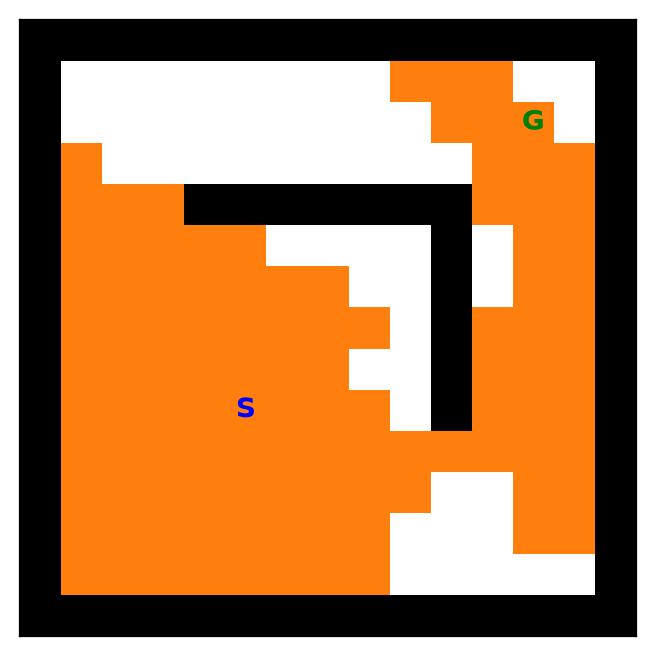

CPU times: total: 0 ns
Wall time: 8.78 ms
Path length: 1120
Reached squares: 132
Action sequence: ['S', 'N', 'N', 'W', 'E', 'E', 'E', 'N', 'S', 'E', 'E', 'S', 'W', 'S', 'S', 'N', 'E', 'N', 'W', 'W', 'E', 'S', 'S', 'W', 'W', 'W', 'N', 'E', 'N', 'N', 'S', 'E', 'W', 'N', 'N', 'E', 'W', 'E', 'W', 'E', 'N', 'N', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'N', 'S', 'N', 'N', 'S', 'E', 'W', 'N', 'S', 'E', 'E', 'W', 'E', 'W', 'N', 'S', 'S', 'E', 'W', 'N', 'N', 'S', 'W', 'E', 'W', 'E', 'N', 'S', 'E', 'N', 'E', 'W', 'S', 'E', 'W', 'W', 'E', 'W', 'S', 'S', 'N', 'S', 'N', 'S', 'N', 'N', 'W', 'W', 'E', 'W', 'S', 'E', 'E', 'W', 'N', 'E', 'S', 'N', 'S', 'W', 'W', 'S', 'E', 'E', 'N', 'E', 'E', 'N', 'S', 'N', 'E', 'E', 'N', 'W', 'E', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'N', 'W', 'N', 'S', 'E', 'N', 'N', 'W', 'S', 'E', 'N', 'E', 'S', 'W', 'E', 'E', 'W', 'N', 'S', 'W', 'S', 'S', 'S', 'W', 'S', 'S', 'E', 'N', 'N', 'W', 'E', 'N', 'S', 'E', 'E', 'W', 'W', 'W', 'N', 'E', 'S', 'S', 'S', 'S', 'W', 'E', 'E', 'E', 'N', '

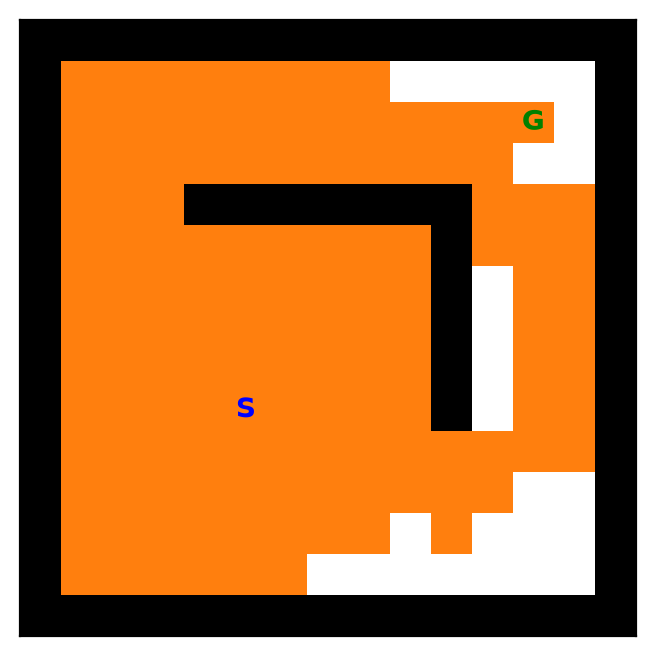

In [483]:
ts.set_order(random = True)

# run it multiple times to see the effect of randomization
for _ in range(5):
    %time result = ts.DFS(maze, check_cycle = False, max_tries = 100000, vis = False, debug_reached = True)

    #result
    ts.show_path(maze, result)
    if result['path'] is None:
        print("No solution found!")

### Run randomized DFS multiple times and use the best solution.

__Note:__ IDS takes a similar amount of time and memory, but is guaranteed optimal.

Directions are checked in random order
CPU times: total: 141 ms
Wall time: 150 ms
Solutions have path_lengths of [86, 52, 56, 44, 52, 68, 72, 62, 86, 50, 60, 92, 86, 70, 78, 106, 44, 58, 52, 40, 44, 46, 64, 70, 80, 48, 76, 62, 44, 68, 28, 98, 106, 70, 98, 34, 64, 88, 42, 90, 66, 64, 96, 90, 78, 66, 70, 90, 54, 68, 92, 66, 114, 50, 68, 82, 42, 82, 56, 60, 54, 72, 48, 54, 84, 50, 50, 36, 102, 46, 88, 38, 68, 74, 68, 64, 30, 36, 88, 78, 66, 54, 64, 78, 72, 50, 54, 84, 62, 92, 76, 34, 68, 108, 78, 62, 58, 50, 66, 76]
Path length: 28
Reached squares: 0
Action sequence: ['S', 'S', 'E', 'E', 'E', 'S', 'E', 'N', 'E', 'S', 'S', 'E', 'N', 'E', 'E', 'N', 'N', 'W', 'N', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'W', 'N']


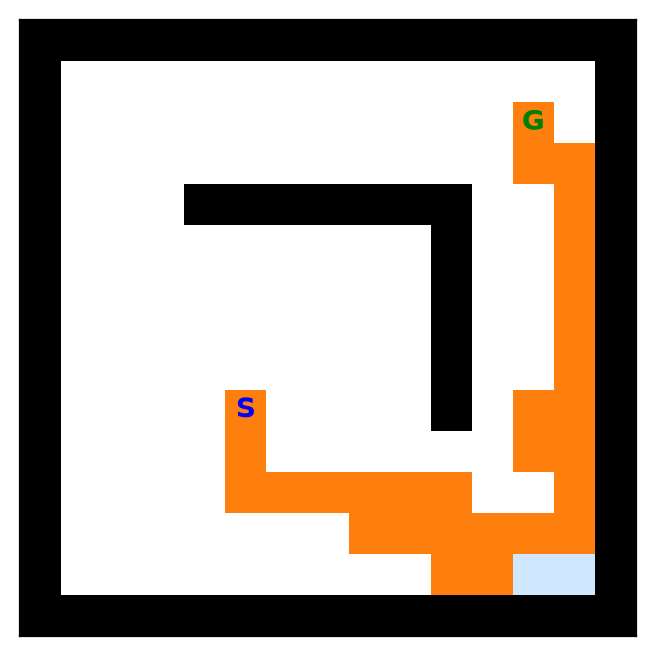

In [484]:
ts.set_order(random = True)

N = 100
%time results = [ ts.DFS(maze, max_tries = 10000, vis = False) for _ in range(N) ]

# check if we found a solution and display the best solution
results = [ r for r in results if not r['path'] is None ]
if len(results) > 0:
    path_lengths = [ len(r['path'])-1 for r in results ]

    print(f"Solutions have path_lengths of {path_lengths}")

    result = results[ts.min_index(path_lengths)]
    ts.show_path(maze, result)
else:
    print("No solution found!")

### Depth limited DFS

Note: The frontier needs to be checked differently during cycle checking!

Directions are checked in random order
CPU times: total: 0 ns
Wall time: 4.01 ms
No solution found.


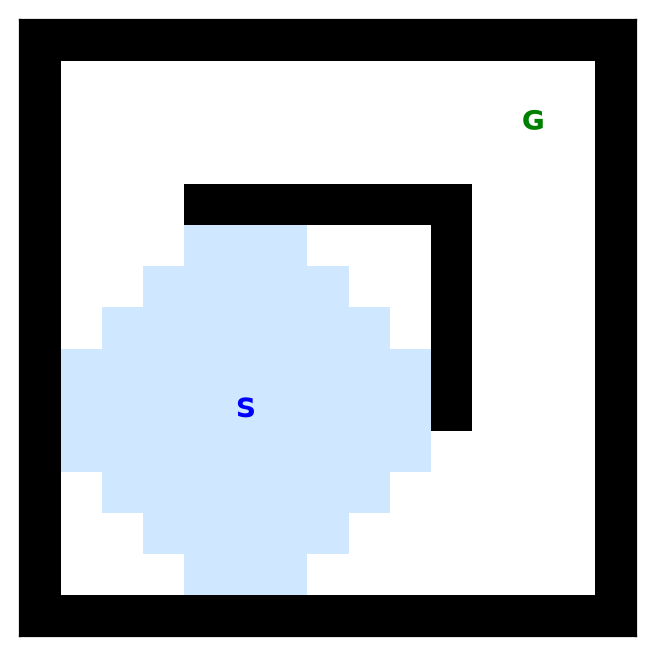

In [485]:
ts.set_order(random = True)

%time result = ts.DFS(maze, limit = 5, frontier_option = 2, max_tries = 100000, vis = False, debug_reached = True)
ts.show_path(maze, result)

In [486]:
import pandas as pd

orders = ["ESWN", "NESW", "SWNE", "WNES"]
limits = range(5, 100, 5)

results_dls = []

for order in orders:
    ts.set_order(order)

    for limit in limits:
        res = ts.DFS(
            maze,
            limit=limit,
            frontier_option=1,
            max_tries=100000,
            check_cycle=True,
            vis=False
        )

        path = res["path"]

        results_dls.append({
            "Thứ tự hướng": order,
            "Limit": limit,
            "Tìm thấy đích": path is not None,
            "Số bước": len(path) - 1 if path is not None else None,
            "Số nút đã xét": res["tries"],
            "Độ sâu lớn nhất": res["max_depth"]
        })

df_dls = pd.DataFrame(results_dls)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", None
):
    display(df_dls)

Directions are checked in the order ['E', 'S', 'W', 'N']
Directions are checked in the order ['N', 'E', 'S', 'W']
Directions are checked in the order ['S', 'W', 'N', 'E']
Directions are checked in the order ['W', 'N', 'E', 'S']


,Thứ tự hướng,Limit,Tìm thấy đích,Số bước,Số nút đã xét,Độ sâu lớn nhất
0,ESWN,5,False,NaN,59,5
1,ESWN,10,False,NaN,424,10
2,ESWN,15,False,NaN,351,15
3,ESWN,20,False,NaN,306,20
4,ESWN,25,False,NaN,945,25
5,ESWN,30,True,30.0,137,30
6,ESWN,35,True,34.0,399,35
7,ESWN,40,True,36.0,90,40
8,ESWN,45,True,36.0,135,45
9,ESWN,50,True,36.0,105,50


In [487]:

# BẢNG TỔNG KẾT DLS THEO THỨ TỰ HƯỚNG

summary_rows = []

for order in orders:
    group = df_dls[df_dls["Thứ tự hướng"] == order]
    found = group[group["Tìm thấy đích"] == True]

    summary_rows.append({
        "Thứ tự hướng": order,
        "Số giới hạn đã thử": len(group),
        "Có tìm thấy đích": not found.empty,
        "Giới hạn tìm thấy đầu tiên": (
            found["Limit"].iloc[0] if not found.empty else "Không tìm thấy"
        ),
        "Số bước của lời giải đầu tiên": (
            found["Số bước"].iloc[0] if not found.empty else None
        )
    })

df_dls_summary = pd.DataFrame(summary_rows)
display(df_dls_summary)

,Thứ tự hướng,Số giới hạn đã thử,Có tìm thấy đích,Giới hạn tìm thấy đầu tiên,Số bước của lời giải đầu tiên
0,ESWN,19,True,30,30.0
1,NESW,19,True,45,44.0
2,SWNE,19,True,20,20.0
3,WNES,19,True,25,24.0


In [488]:
# BẢNG 2 - TỔNG KẾT THEO THỨ TỰ HƯỚNG

summary = (
    df_dls[df_dls["Số bước"].notna()]
    .groupby("Thứ tự hướng")
    .agg({
        "Số bước": ["count", "min", "max"]
    })
)

summary.columns = [
    "Số lần tìm thấy đích",
    "Ít bước nhất",
    "Nhiều bước nhất"
]

summary = summary.reindex(orders).reset_index()

display(summary)

,Thứ tự hướng,Số lần tìm thấy đích,Ít bước nhất,Nhiều bước nhất
0,ESWN,14,30.0,36.0
1,NESW,8,44.0,88.0
2,SWNE,16,20.0,52.0
3,WNES,15,24.0,26.0


### IDS

__Notes:__ 

* IDS with DFS does not store reached squares, so gray areas are not shown!

* IDS depends on the cycle checking of DFS and therefore is also affected by these problems.

Directions are checked in the order ['S', 'W', 'N', 'E']
CPU times: total: 2.75 s
Wall time: 2.84 s
Path length: 16
Reached squares: 0
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


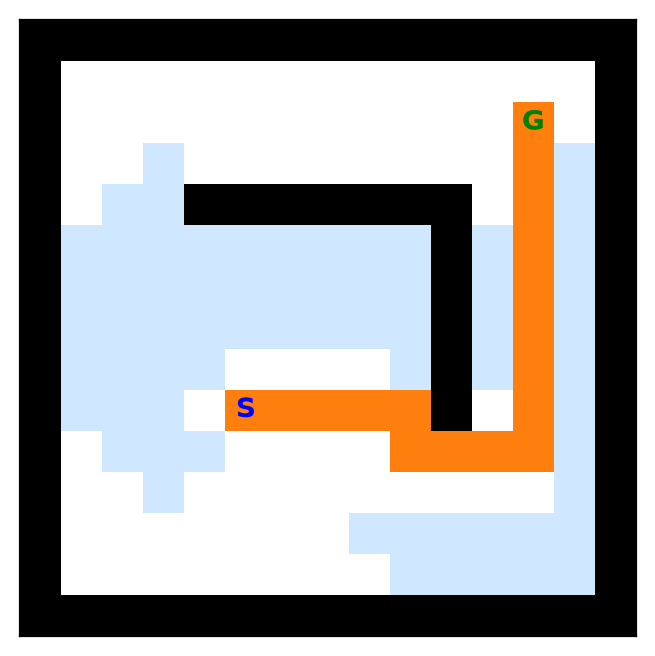

Số lần tăng giới hạn độ sâu: 16
Tổng số nút đã mở rộng: 472047
Số lượt chạy DFS: 17
Thời gian chạy (giây): 2.8369386000558734


In [489]:

ts.set_order("SWNE")
%time result = ts.IDS(maze, frontier_option=2, max_tries=100000)

# Hiển thị đường đi tìm được
ts.show_path(maze, result)

# Thống kê kết quả IDS
print("Số lần tăng giới hạn độ sâu:", result["limit_increases"])
print("Tổng số nút đã mở rộng:", result["total_expanded"])
print("Số lượt chạy DFS:", len(result["per_iteration"]))
print("Thời gian chạy (giây):", result["time"])

In [490]:

import pandas as pd

df_ids = pd.DataFrame(
    result["per_iteration"],
    columns=[
        "Giới hạn độ sâu",
        "Số nút mở rộng",
        "Frontier lớn nhất",
        "Tìm thấy lời giải"
    ]
)

display(df_ids)

,Giới hạn độ sâu,Số nút mở rộng,Frontier lớn nhất,Tìm thấy lời giải
0,0,1,1,False
1,1,5,4,False
2,2,17,6,False
3,3,49,8,False
4,4,133,10,False
5,5,348,11,False
6,6,868,12,False
7,7,2034,13,False
8,8,4521,15,False
9,9,9609,16,False


In [491]:

# Lượt cuối cùng tìm thấy lời giải
successful = df_ids[df_ids["Tìm thấy lời giải"] == True]

if not successful.empty:
    print("Giới hạn tìm thấy lời giải:",
          successful.iloc[-1]["Giới hạn độ sâu"])
    print("Số lần tăng giới hạn:",
          result["limit_increases"])
else:
    print("Chưa tìm thấy lời giải trong các lượt IDS.")

Giới hạn tìm thấy lời giải: 16
Số lần tăng giới hạn: 16


### Greedy Best-First Search (GBFS)

In [492]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

Directions are checked in random order
CPU times: total: 0 ns
Wall time: 2.01 ms
Path length: 24
Reached squares: 65
Action sequence: ['N', 'N', 'N', 'E', 'N', 'E', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


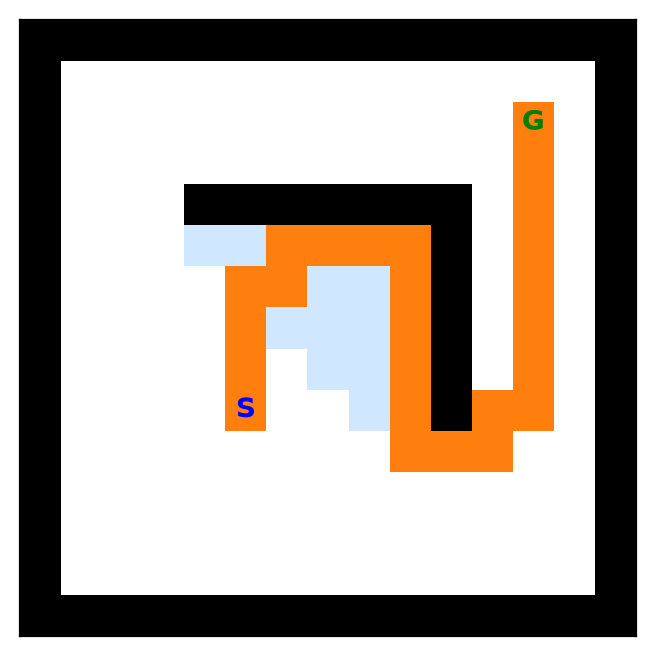

In [493]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", debug = False, vis = False)
ts.show_path(maze, result)

### A* Search

Directions are checked in random order
CPU times: total: 0 ns
Wall time: 1 ms
Path length: 16
Reached squares: 81
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'E', 'N', 'N', 'N', 'N', 'N', 'N']


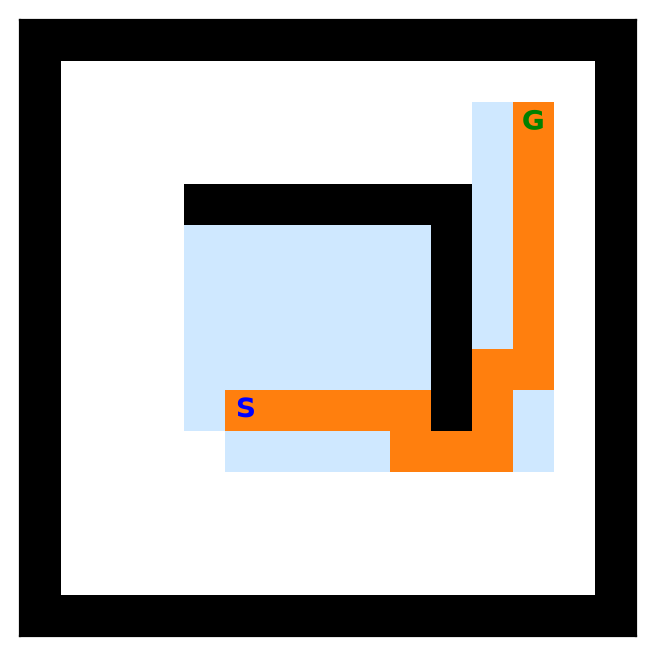

In [494]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False)
ts.show_path(maze, result)

### Weighted A* Search

$W > 1$ tends towards GBFS (optimality is not guaranteed)

Directions are checked in random order
CPU times: total: 0 ns
Wall time: 1 ms
Path length: 16
Reached squares: 68
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


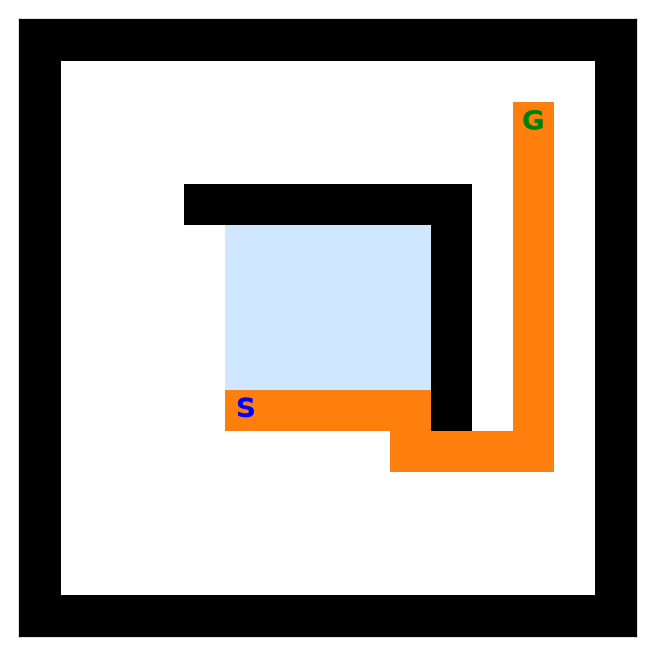

In [495]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", W = 1+1e-9, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 1 ms
Path length: 16
Reached squares: 66
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


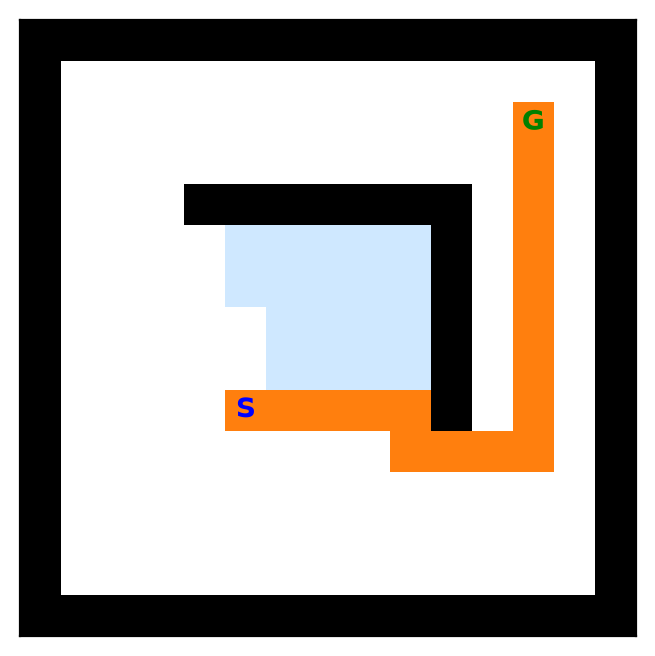

In [496]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 5, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 1.16 ms
Path length: 16
Reached squares: 64
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


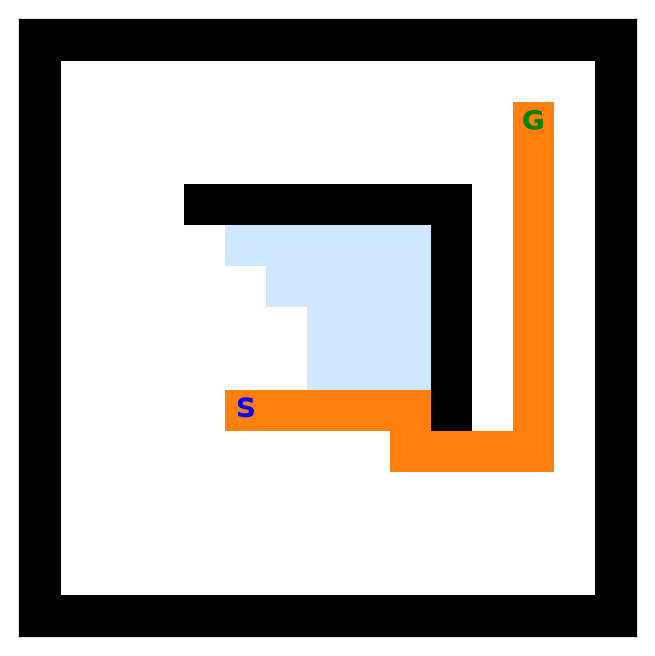

In [497]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 1000, debug = False, vis = False)
ts.show_path(maze, result)

$W<1$ tends towards Uniform-Cost Search/BFS (optimality is guaranteed)

CPU times: total: 0 ns
Wall time: 1.01 ms
Path length: 16
Reached squares: 124
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


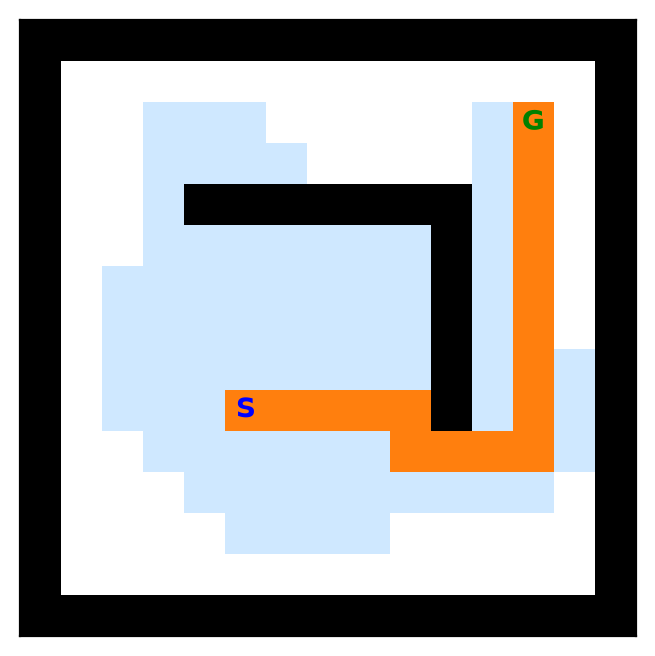

In [498]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .7, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 31.2 ms
Wall time: 2 ms
Path length: 16
Reached squares: 155
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'E', 'N', 'N', 'N', 'N', 'N', 'N']


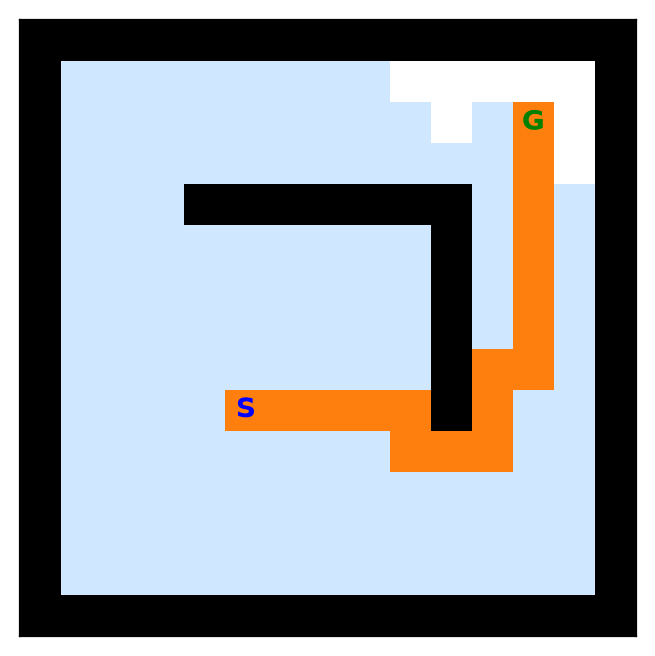

In [499]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .0001, debug = False, vis = False)
ts.show_path(maze, result)

### Compare Timing

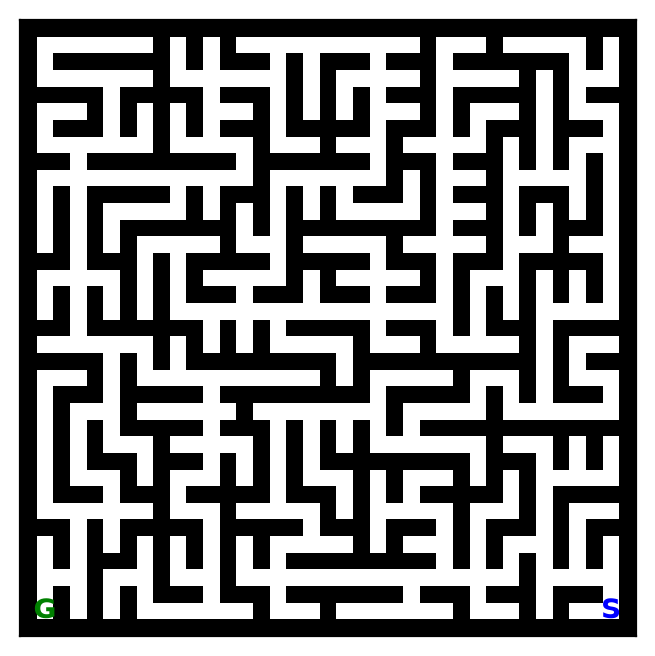

Directions are checked in random order


In [500]:
#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("L_maze.txt", "r")
#f = open("loops_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

ts.show_maze(maze)

ts.set_order(random=True)


In [501]:
import timeit
import math

reps = 10

times = {}

algorithms = ["BFS", "DFS", "GBFS", "A*"]

### FIXME: add IDS

for a in algorithms:
    times[a] = math.ceil(timeit.timeit(stmt = f'ts.best_first_search(maze, strategy = "{a}", debug = False, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)
    
times['DFS(no reached)'] = math.ceil(timeit.timeit(stmt = f'ts.DFS(maze, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

times['IDS'] = math.ceil(timeit.timeit(stmt = f'ts.IDS(maze, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

In [502]:
import pandas as pd
df = pd.DataFrame(times, index = ["time in micro seconds"])
df

,BFS,DFS,GBFS,A*,DFS(no reached),IDS
time in micro seconds,5707,5366,4225,7295,13998,1328583


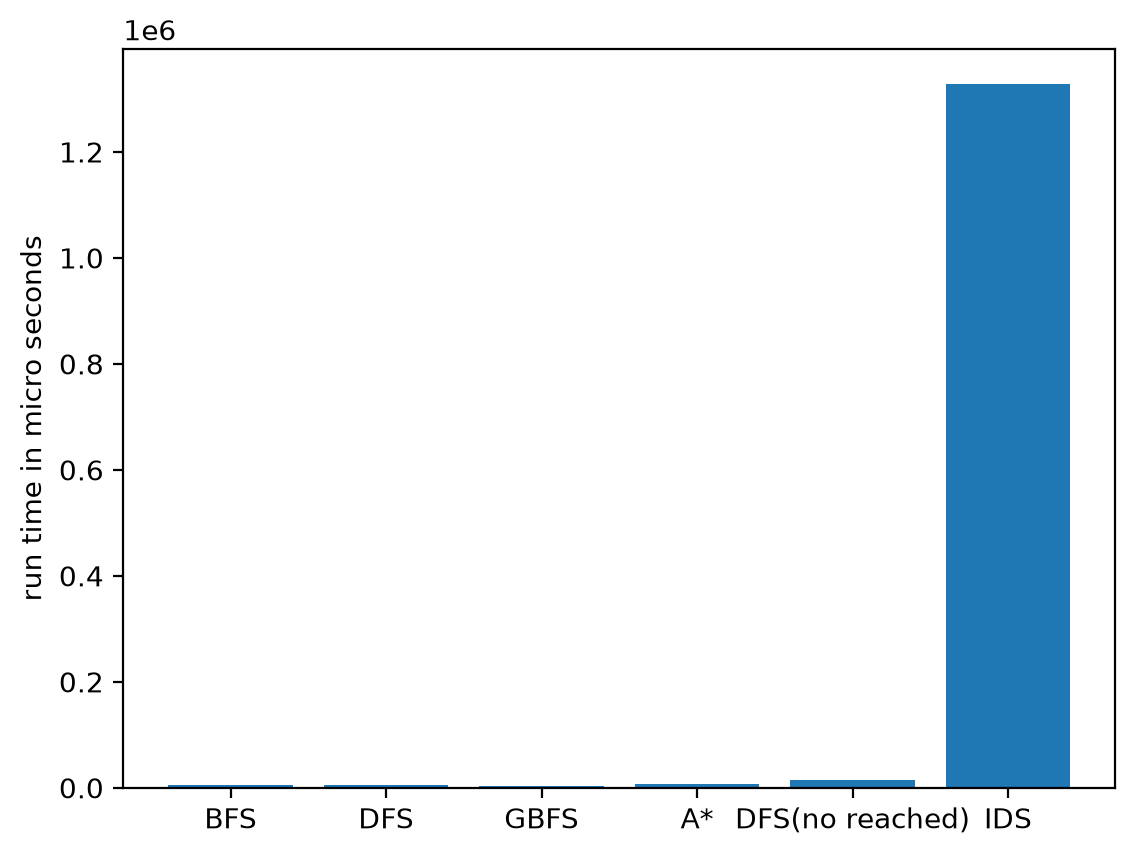

In [503]:
import matplotlib.pyplot as plt

plt.bar(df.columns, height = df.iloc[0])
plt.ylabel("run time in micro seconds")
plt.show()